## KMA/MSM 2026/2027 - Úloha 2

### Téma: Testy o poloze — jednovýběrové, dvouvýběrové a vícevýběrové testy, ANOVA, vícerozměrné testy

#### Zvolený dataset: Fish Market (https://www.kaggle.com/datasets/aungpyaeap/fish-market, https://github.com/Ankit152/Fish-Market/blob/main/Fish.csv)

In [ ]:
import pandas as pd
df = pd.read_csv('Fish.csv')
df = df[df['Weight'] > 0]  # odstranění zjevně chybného pozorování s Weight = 0
df['Species'].value_counts()

Species
Perch        56
Bream        35
Roach        19
Pike         17
Smelt        14
Parkki       11
Whitefish     6
Name: count, dtype: int64

In [ ]:
variables = ['Length3', 'Height', 'Weight']

# vybrány pouze čtyři nejpočetnější druhy u kterých má smysl porovnávat fyzické vlastnosti
classes = ['Bream', 'Perch', 'Roach', 'Pike']
groups = {s: df[df['Species'] == s] for s in classes}
group_a = groups['Bream']   # hlavní skupina pro jednovýběrové testy (vysoký počet pozorování + ve všech proměnných vyhovuje testu normality)

df.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


### Test normality - Shapiro-Wilk test

Nulová hypotéza ($H_0$): Data pocházejí z normálního rozdělení.
Alternativní hypotéza ($H_1$): Data nepocházejí z normálního rozdělení.

Na rozdíl od velkého datasetu s tisíci pozorováními máme zde jen desítky ryb na druh, takže Shapiro-Wilk test má omezenou sílu a nezamítnutí $H_0$ není důkazem normality. Testujeme proto všechny čtyři druhy a doplňujeme grafy.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

rows = []
for s in classes:
    for var in variables:
        w, p = stats.shapiro(groups[s][var])
        rows.append({'Druh': s, 'Proměnná': var, 'n': len(groups[s]), 'Testová statistika': round(w, 4), 'p-hodnota': p, 'Závěr': 'nezamítáme H0' if p > 0.05 else 'zamítáme H0'})


pd.DataFrame(rows).style.format({'p-hodnota': '{:.4f}'}).hide(axis='index')

Druh,Proměnná,n,W,p-hodnota,Závěr
Bream,Length3,35,0.983900,0.8763,nezamítáme H0
Bream,Height,35,0.970200,0.4483,nezamítáme H0
Bream,Weight,35,0.959200,0.2169,nezamítáme H0
Perch,Length3,56,0.935800,0.0052,zamítáme H0
Perch,Height,56,0.907900,0.0004,zamítáme H0
Perch,Weight,56,0.816800,0.0000,zamítáme H0
Roach,Length3,19,0.977000,0.9023,nezamítáme H0
Roach,Height,19,0.966200,0.6988,nezamítáme H0
Roach,Weight,19,0.898000,0.0448,zamítáme H0
Pike,Length3,17,0.924200,0.1739,nezamítáme H0


#### QQ grafy a histogramy

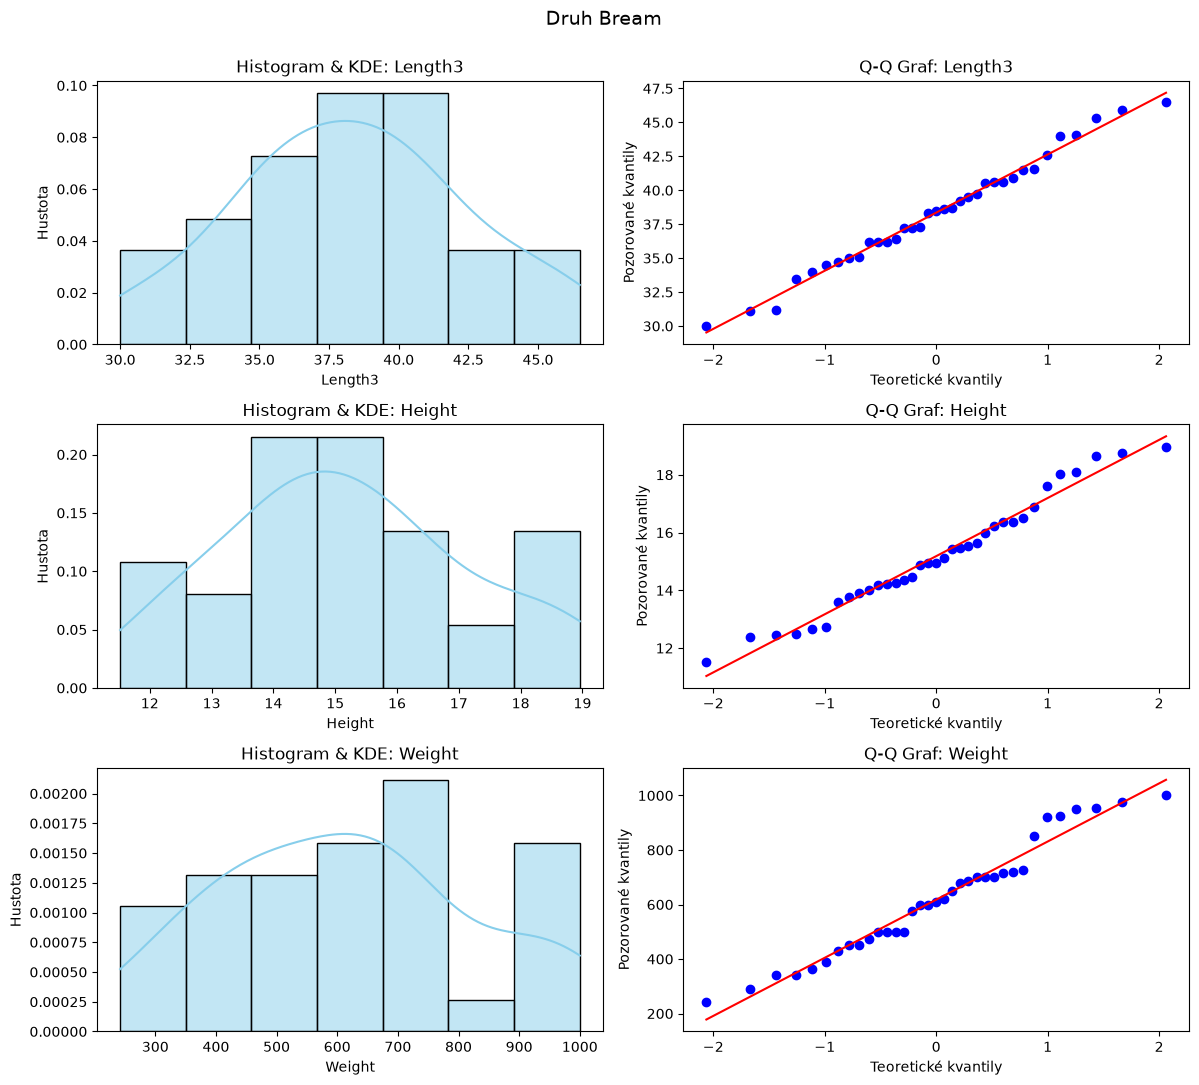

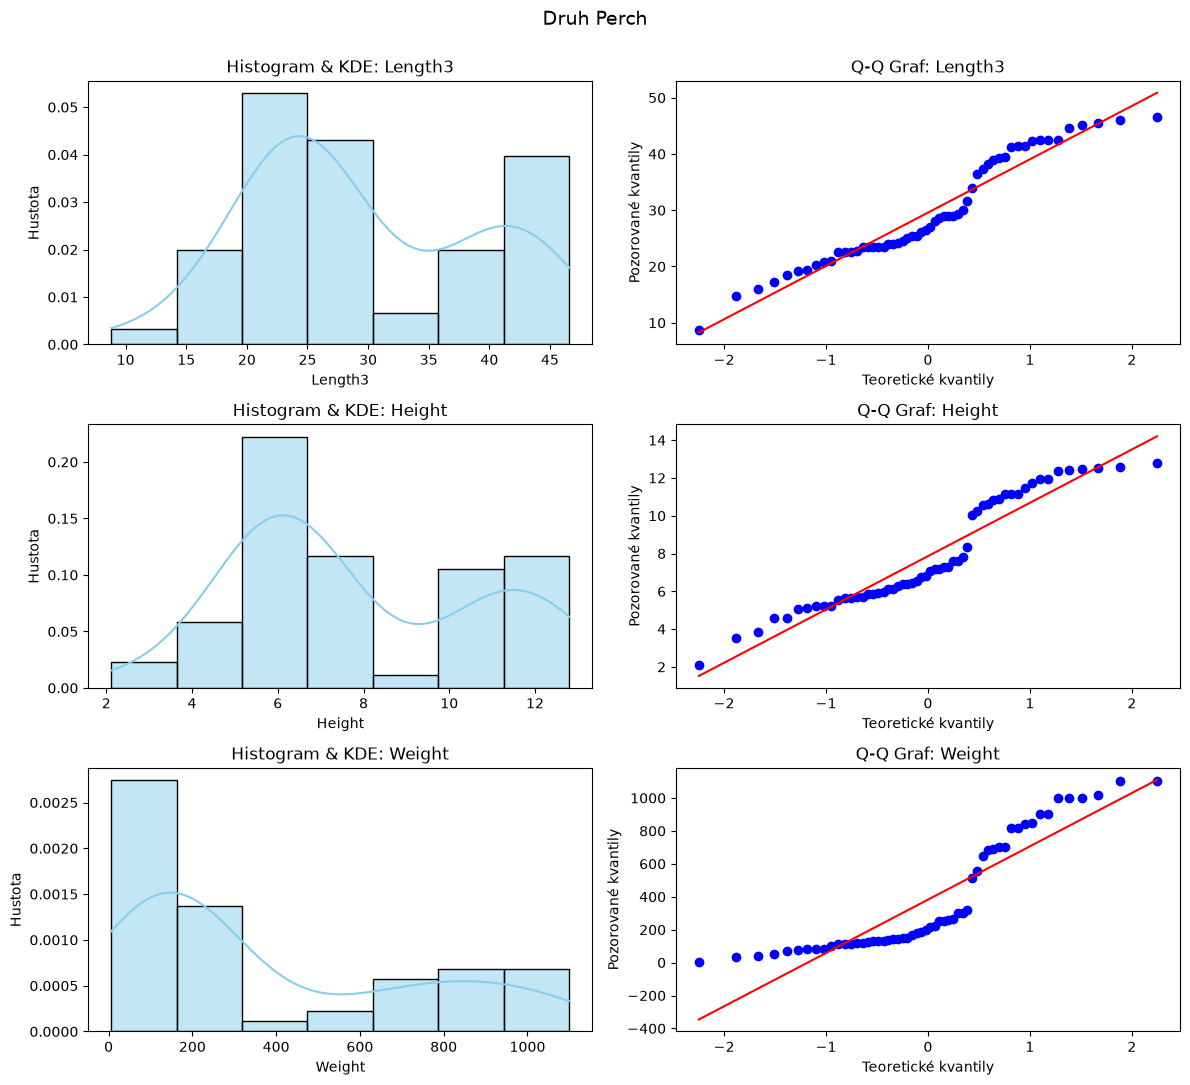

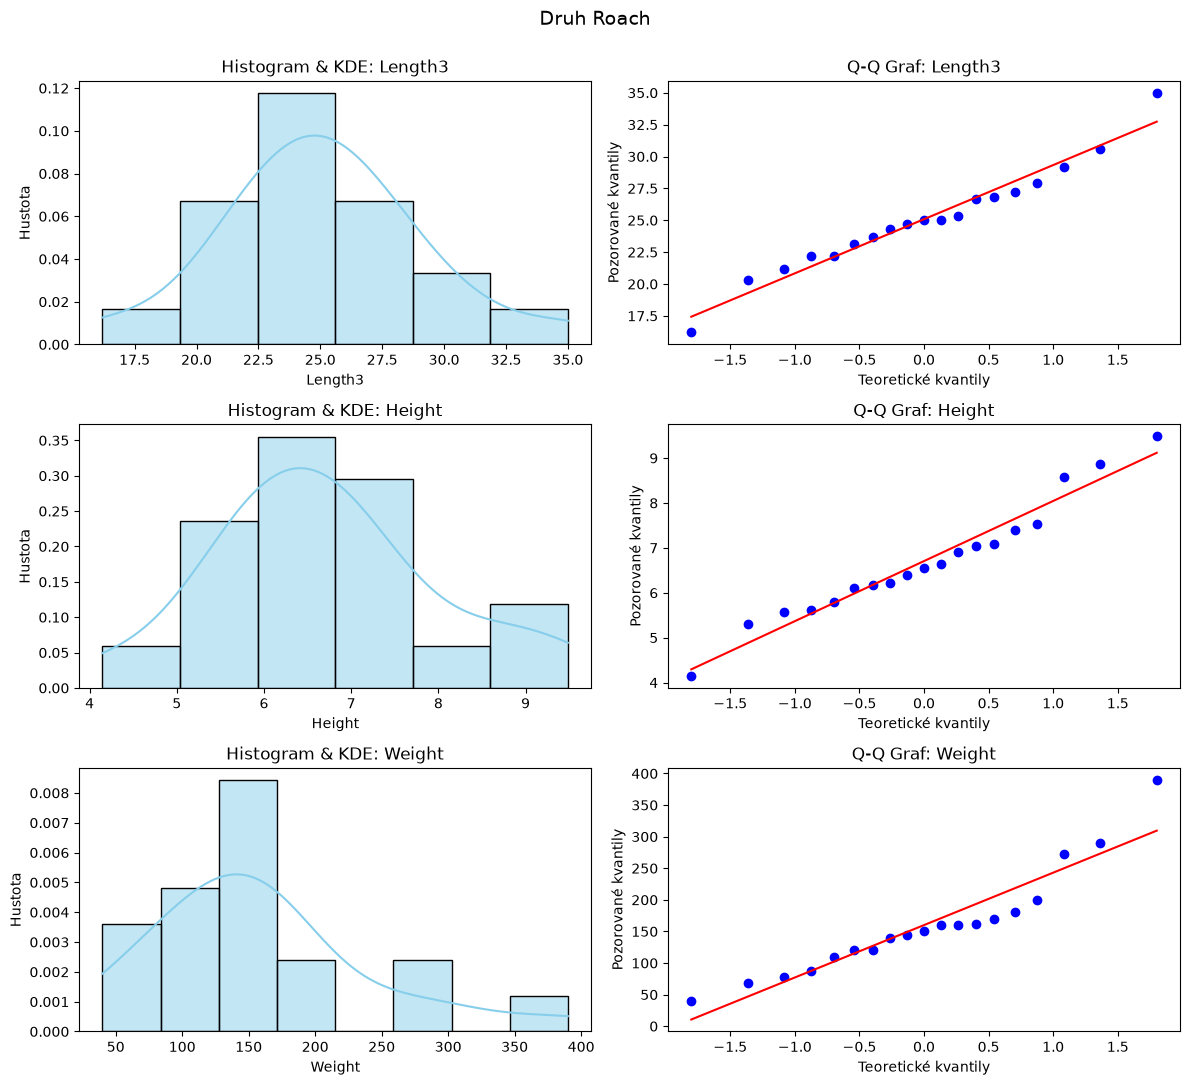

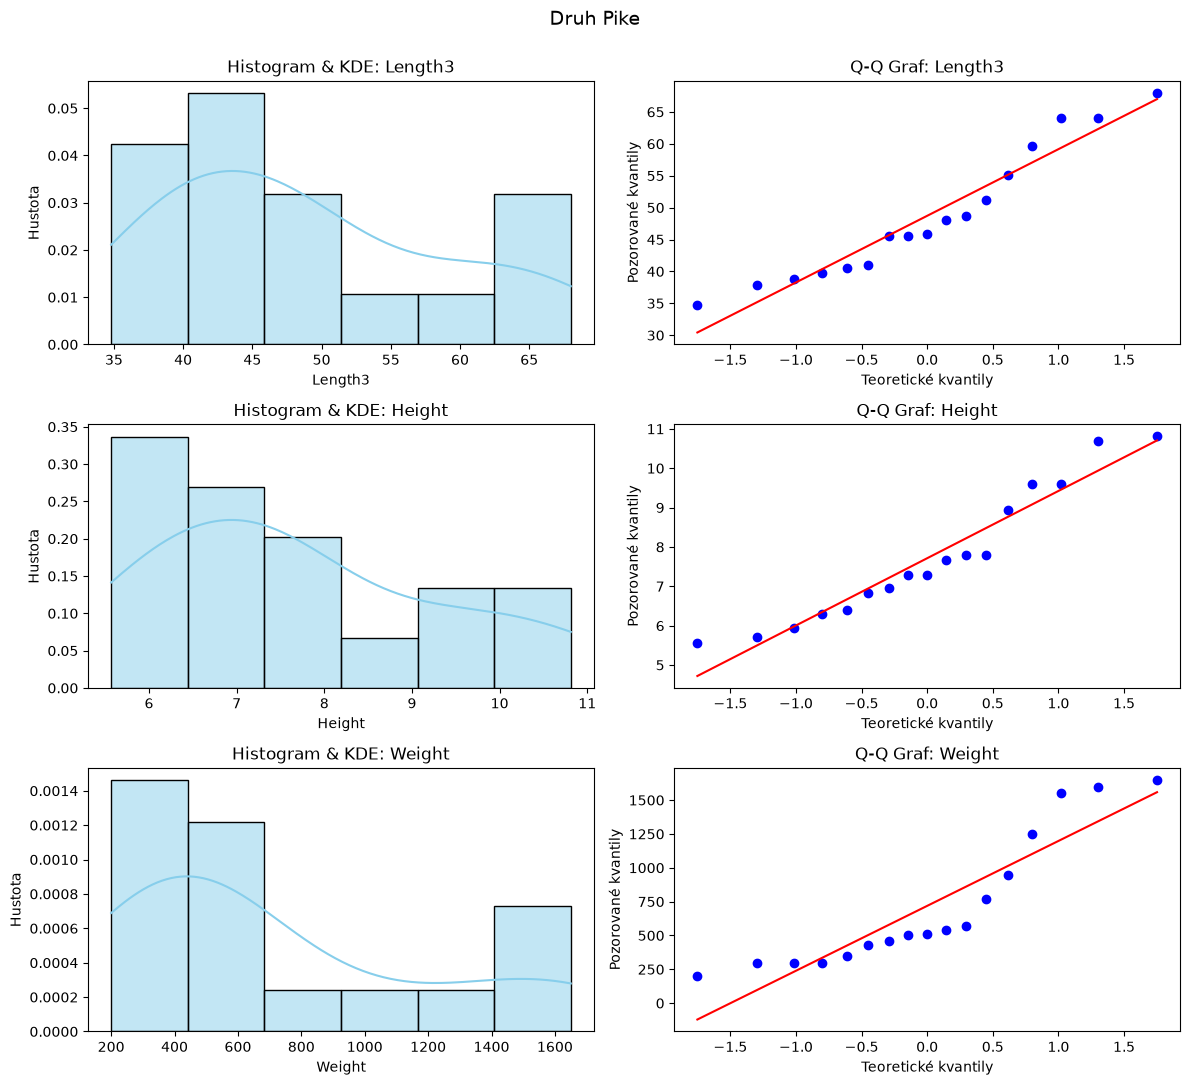

In [32]:
for s in ['Bream', 'Perch', 'Roach', 'Pike']:
    fig, axes = plt.subplots(len(variables), 2, figsize=(12, 3.6 * len(variables)))
    fig.suptitle(f'Druh {s}', y=1.0, fontsize=14)

    for i, var in enumerate(variables):
        data = groups[s][var]

        sns.histplot(data, kde=True, ax=axes[i, 0], color='skyblue', stat='density')
        axes[i, 0].set_title(f'Histogram & KDE: {var}')
        axes[i, 0].set_xlabel(var)
        axes[i, 0].set_ylabel('Hustota')

        stats.probplot(data, dist='norm', plot=axes[i, 1])
        axes[i, 1].set_title(f'Q-Q Graf: {var}')
        axes[i, 1].set_xlabel('Teoretické kvantily')
        axes[i, 1].set_ylabel('Pozorované kvantily')

    plt.tight_layout()
    plt.show()

Shapiro-Wilk test nezamítá normalitu u druhu Bream v žádné ze tří proměnných ($p$ od 0,22 do 0,88), proto jej používáme jako hlavní skupinu pro jednovýběrové testy. U druhů Roach a Pike normalitu nezamítáme pro `Length3` a `Height`, ale zamítáme ji pro `Weight` ($p = 0{,}045$, resp. $p = 0{,}004$). U druhu Perch zamítáme normalitu ve všech třech proměnných ($p \leq 0{,}005$). Q-Q grafy ukazují, že Perch a Pike mají sešikmené rozdělení.


### Jednovýběrové testy

#### Jako parametrický test je vždy zvolen Jednovýběrový t-test, jako neparametrický test Wilcoxonův test

Proměnná `Height`:
Ověřujeme, zda se výška těla jedinců druhu Bream statisticky významně odlišuje od průměru celého datasetu (všech druhů dohromady).
* **Parametrická hypotéza:**
  * $H_0: \mu = \mu_0$ (Průměrná výška těla u druhu Bream je rovna celkovému průměru datasetu)
  * $H_1: \mu \neq \mu_0$ (Průměrná výška těla u druhu Bream se liší od celkového průměru)
* **Neparametrická hypotéza:**
  * $H_0: m = m_0$ (Medián výšky těla u druhu Bream je roven celkovému mediánu datasetu)
  * $H_1: m \neq m_0$ (Medián výšky těla u druhu Bream se liší od celkového mediánu)

Proměnná `Length3`:
Testujeme, zda se průměrná délka ryb druhu Bream liší od referenční hodnoty $40\,\text{cm}$. Hodnota je zvolena pouze orientačně (uvádí se délka 30-55 cm)
* **Parametrická hypotéza:**
  * $H_0: \mu = 40\text{ cm}$ (Průměrná délka ve skupině Bream je rovna $40\text{ cm}$)
  * $H_1: \mu \neq 40\text{ cm}$ (Průměrná délka ve skupině Bream se liší od $40\text{ cm}$)
* **Neparametrická hypotéza:**
  * $H_0: m = 40\text{ cm}$ (Medián délky ve skupině Bream je roven $40\text{ cm}$)
  * $H_1: m \neq 40\text{ cm}$ (Medián délky ve skupině Bream se liší od $40\text{ cm}$)

Proměnná `Weight`:
Testujeme, zda se průměrná hmotnost ryb druhu Bream liší od referenční hodnoty $\mu_0 = 600\text{ g}$ (opět ilustračně zvolená hodnota, nikoli údaj z literatury).
* **Parametrická hypotéza:**
  * $H_0: \mu = 600\text{ g}$ (Průměrná hmotnost ve skupině Bream je rovna $600\text{ g}$)
  * $H_1: \mu \neq 600\text{ g}$ (Průměrná hmotnost ve skupině Bream se liší od $600\text{ g}$)
* **Neparametrická hypotéza:**
  * $H_0: m = 600\text{ g}$ (Medián hmotnosti ve skupině Bream je roven $600\text{ g}$)
  * $H_1: m \neq 600\text{ g}$ (Medián hmotnosti ve skupině Bream se liší od $600\text{ g}$)


In [ ]:
data_h = group_a['Height']
mu0_h = df['Height'].mean()
m0_h = df['Height'].median()

t_stat_h, p_val_t_h = stats.ttest_1samp(data_h, popmean=mu0_h)
w_stat_h, p_val_w_h = stats.wilcoxon(data_h - m0_h)

print(f"Height | Výběrový průměr = {data_h.mean():.2f} vs. mu_0 = {mu0_h:.2f} | t-test p = {p_val_t_h:.4e}")
print(f"Height | Výběrový medián = {data_h.median():.2f} vs. m_0 = {m0_h:.2f} | Wilcoxon p = {p_val_w_h:.4e}")


data_l = group_a['Length3']
ref_l = 40.0

t_stat_l, p_val_t_l = stats.ttest_1samp(data_l, popmean=ref_l)
w_stat_l, p_val_w_l = stats.wilcoxon(data_l - ref_l)

print(f"Length3 | Výběrový průměr = {data_l.mean():.2f} cm vs. {ref_l} cm | t-test p = {p_val_t_l:.4e}")
print(f"Length3 | Výběrový medián = {data_l.median():.2f} cm vs. {ref_l} cm | Wilcoxon p = {p_val_w_l:.4e}")


data_w = group_a['Weight']
ref_w = 600.0

t_stat_w, p_val_t_w = stats.ttest_1samp(data_w, popmean=ref_w)
w_stat_w, p_val_w_w = stats.wilcoxon(data_w - ref_w)

print(f"Weight | Výběrový průměr = {data_w.mean():.2f} g vs. {ref_w} g | t-test p = {p_val_t_w:.4e}")
print(f"Weight | Výběrový medián = {data_w.median():.2f} g vs. {ref_w} g | Wilcoxon p = {p_val_w_w:.4e}")

Height | Výběr průměr = 15.18 vs. mu_0 = 8.99 | t-test p = 1.9472e-19
Height | Výběr medián = 14.95 vs. m_0  = 7.79 | Wilcoxon p = 5.8208e-11
Length3 | Výběr průměr = 38.35 cm vs. 40.0 cm | t-test p = 2.5198e-02
Length3 | Výběr medián = 38.50 cm vs. 40.0 cm | Wilcoxon p = 3.6004e-02
Weight | Výběr průměr = 617.83 g vs. 600.0 g | t-test p = 6.1739e-01
Weight | Výběr medián = 610.00 g vs. 600.0 g | Wilcoxon p = 7.8844e-01


Proměnná `Height`:
Oba testy zamítají $H_0$. Průměrná výška těla u druhu Bream (15,18) je o více než 6 jednotek vyšší než průměr celého datasetu (8,99), medián 14,95 oproti 7,79.

Proměnná `Length3`:
Oba testy zamítají $H_0$ na hladině $5\,\%$. 

Proměnná `Weight`:
Nezamítáme $H_0$ u žádného z testů ($p = 0{,}62$ u t-testu, $p = 0{,}79$ u Wilcoxonova testu). Průměr 617,8 g a medián 610 g jsou blízko referenci $600\,\text{g}$. Nezamítnutí neznamená, že je střední hodnota přesně $600\,\text{g}$, jen že data odchylku neprokazují.

### Dvouvýběrové testy

Pro každou ze tří proměnných porovnáváme polohu mezi všemi dvojicemi druhů (6 dvojic).

* **Parametrický přístup:** Dvouvýběrový Welch t-test.
  * $H_0: \mu_i = \mu_j$ (Střední hodnoty dané proměnné se u druhů $i$ a $j$ rovnají)
  * $H_1: \mu_i \neq \mu_j$ (Střední hodnoty dané proměnné se u druhů $i$ a $j$ liší)
* **Neparametrický přístup:** Mann-Whitney U test.
  * $H_0$: Rozdělení proměnné jsou u druhů $i$ a $j$ shodná
  * $H_1$: Rozdělení proměnné se u druhů $i$ a $j$ liší

In [31]:
from itertools import combinations

alpha = 0.05
pairs = list(combinations(classes, 2))

rows = []
for var in variables:
    for g1, g2 in pairs:
        d1, d2 = groups[g1][var], groups[g2][var]
        p_w = stats.ttest_ind(d1, d2, equal_var=False).pvalue
        p_mw = stats.mannwhitneyu(d1, d2, alternative='two-sided').pvalue
        rows.append({
            'Proměnná': var,
            'Dvojice': f'{g1} vs {g2}',
            'Průměr 1': d1.mean(),
            'Průměr 2': d2.mean(),
            'p (Welch)': p_w,
            'Welch: zamítáme H0?': 'ano' if p_w < alpha else 'ne',
            'p (MW-U)': p_mw,
            'MW-U: zamítáme H0?': 'ano' if p_mw < alpha else 'ne',
        })

res = pd.DataFrame(rows)

print('DVOUVÝBĚROVÉ TESTY (α = 0.05, bez korekce):')
num_cols = ['Průměr 1', 'Průměr 2', 'p (Welch)', 'p (MW-U)']
res.style.format({c: '{:.4g}' for c in num_cols}).hide(axis='index')

DVOUVÝBĚROVÉ TESTY (α = 0.05, bez korekce):


Proměnná,Dvojice,Průměr 1,Průměr 2,p (Welch),Welch: zamítáme H0?,p (MW-U),MW-U: zamítáme H0?
Length3,Bream vs Perch,38.35,29.57,4.433e-08,ano,4.357e-05,ano
Length3,Bream vs Roach,38.35,25.08,1.301e-13,ano,4.61e-09,ano
Length3,Bream vs Pike,38.35,48.72,0.0007197,ano,0.0001165,ano
Length3,Perch vs Roach,29.57,25.08,0.00606,ano,0.1454,ne
Length3,Perch vs Pike,29.57,48.72,3.028e-07,ano,5.539e-07,ano
Length3,Roach vs Pike,25.08,48.72,1.513e-08,ano,3.951e-07,ano
Height,Bream vs Perch,15.18,7.862,6.658e-25,ano,6.882e-15,ano
Height,Bream vs Roach,15.18,6.706,1.636e-24,ano,1.814e-09,ano
Height,Bream vs Pike,15.18,7.714,1.212e-16,ano,6.883e-09,ano
Height,Perch vs Roach,7.862,6.706,0.02027,ano,0.3208,ne


#### Vizualizace předem spočítaných hodnot:

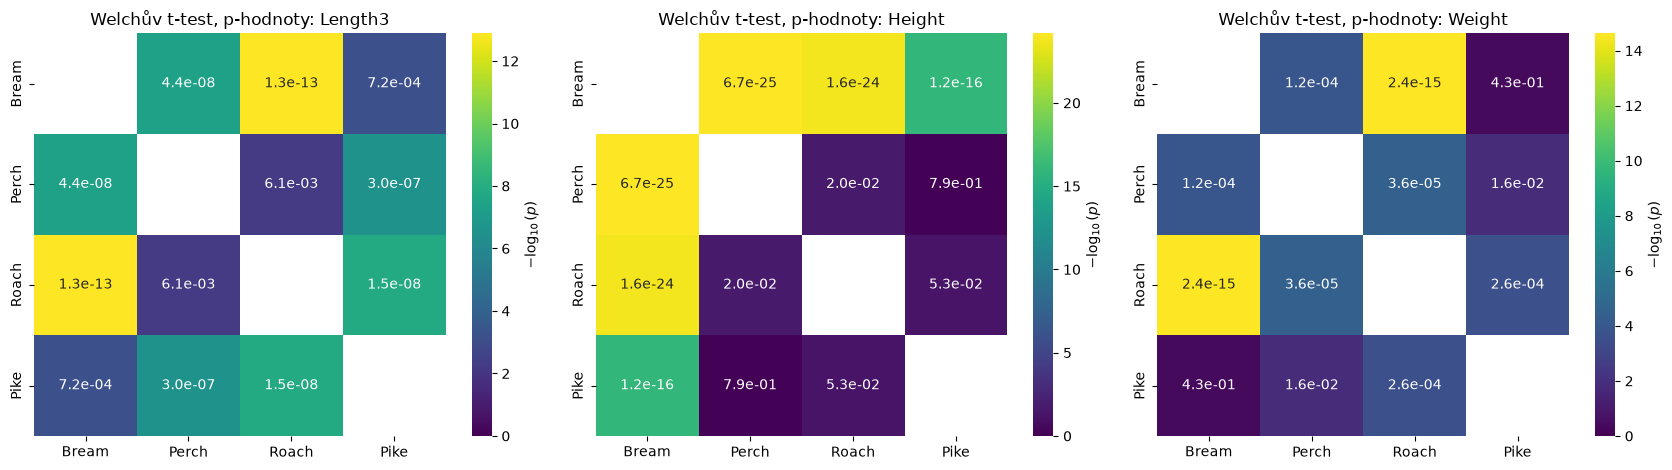

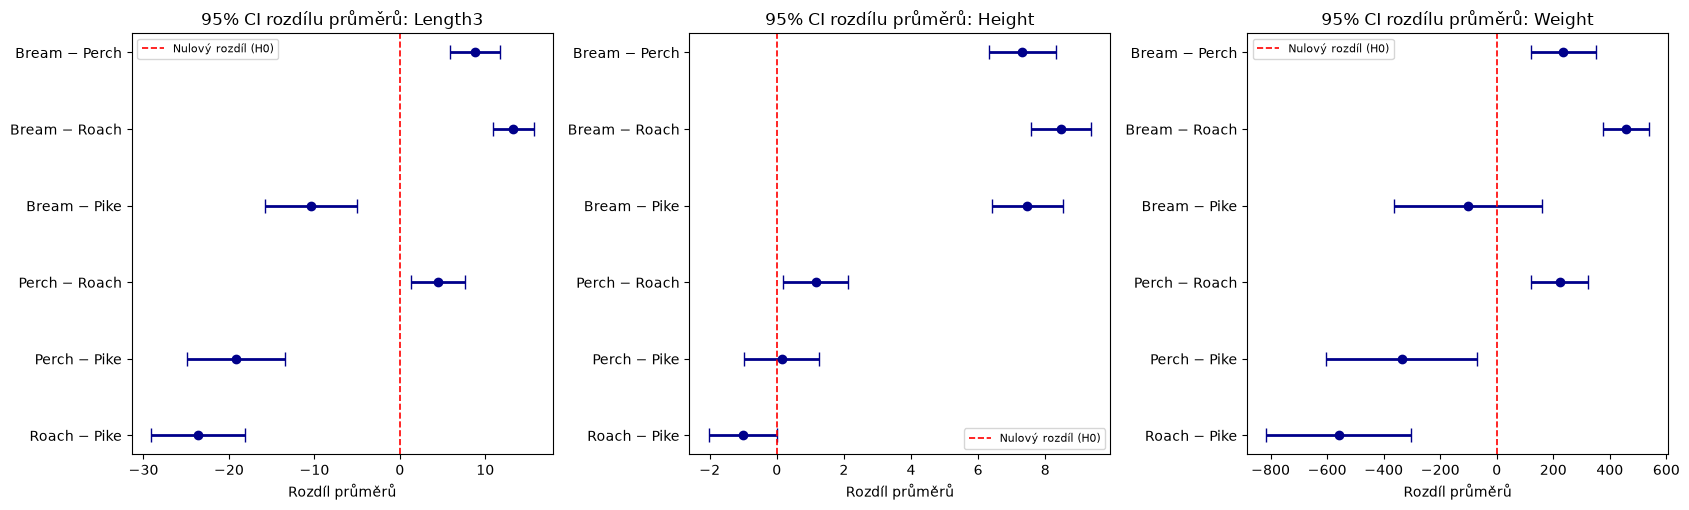

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

for idx, var in enumerate(variables):
    p_mat = pd.DataFrame(np.nan, index=classes, columns=classes)

    for g1, g2 in pairs:
        p = res[(res['Proměnná'] == var) & (res['Dvojice'] == f'{g1} vs {g2}')]['p (Welch)'].iloc[0]
        p_mat.loc[g1, g2] = p_mat.loc[g2, g1] = p

    score = -np.log10(p_mat.clip(lower=1e-300))
    annot = np.array([[('' if np.isnan(p) else f'{p:.1e}') for p in row] for row in p_mat.values])

    sns.heatmap(score, annot=annot, fmt='', mask=p_mat.isna(), cmap='viridis',
                vmin=0, cbar=True, cbar_kws={'label': r'$-\log_{10}(p)$'}, ax=axes[idx])
    axes[idx].set_title(f'Welchův t-test, p-hodnoty: {var}')

plt.tight_layout()
plt.show()

# 2) 95% CI rozdílu průměrů pro všechny dvojice
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

for idx, var in enumerate(variables):
    labels, diffs, lows, highs = [], [], [], []

    for g1, g2 in pairs:
        d1, d2 = groups[g1][var], groups[g2][var]

        ci = stats.ttest_ind(d1, d2, equal_var=False).confidence_interval(confidence_level=0.95)

        labels.append(f'{g1} − {g2}')
        diffs.append(d1.mean() - d2.mean())
        lows.append(ci.low)
        highs.append(ci.high)

    y = np.arange(len(labels))
    xerr = [np.array(diffs) - np.array(lows), np.array(highs) - np.array(diffs)]

    axes[idx].errorbar(diffs, y, xerr=xerr, fmt='o', color='darkblue', capsize=5, linewidth=2)
    axes[idx].axvline(0, color='red', linestyle='--', linewidth=1.2, label='Nulový rozdíl (H0)')
    axes[idx].set_yticks(y)
    axes[idx].set_yticklabels(labels)
    axes[idx].invert_yaxis()
    axes[idx].set_title(f'95% CI rozdílu průměrů: {var}')
    axes[idx].set_xlabel('Rozdíl průměrů')
    axes[idx].legend(loc='best', fontsize=8)

plt.tight_layout()
plt.show()

Vidíme, že druhy se vzájemně liší od ostatních a většina nulových hypotéz zůstává zamítnuta. Protože data u druhů Perch a Pike jsou zešikmená a nesplňují předpoklad normality, je nutné vzít výsledky parametrického testu s rezervou zaměřit se na Mann-Whitneyův U test, který  odhalil, že rozdíly mezi druhy Perch a Roach nejsou ani u jedné z měřených proměnných statisticky významné, ačkoliv Welchův test je jako významné označil. Druh Bream se výrazně liší od ostatních u proměnné `Height`, což potvrzují velmi nízké p-hodnoty i vykreslený interval spolehlivosti. Celkově testy ukazují že všechny druhy ryb se od sebe nějakým způsobem liší.



### Vícevýběrové testy o poloze

Protože u velkého množství proměnných není splněna podmínka normality, pro vícevýběrové testy je použit Kruskal-Wallis test

* **todo:** c.
  * H_0: Všechny skupiny mají stejné rozdělění
  * H_1: Alespoň jedna skupina má rozdělení posunuté oproti ostatním


In [52]:
from scipy.stats import kruskal
import scikit_posthocs as sp

for var in variables:
    stat, p_value = kruskal(
        groups['Bream'][var],
        groups['Perch'][var],
        groups['Roach'][var],
        groups['Pike'][var]
    )
    print(f"{var}: H = {stat:.4f}, p = {p_value:.4e}")



Length3: H = 54.1743, p = 1.0300e-11
Height: H = 74.3300, p = 5.0432e-16
Weight: H = 38.7146, p = 1.9949e-08


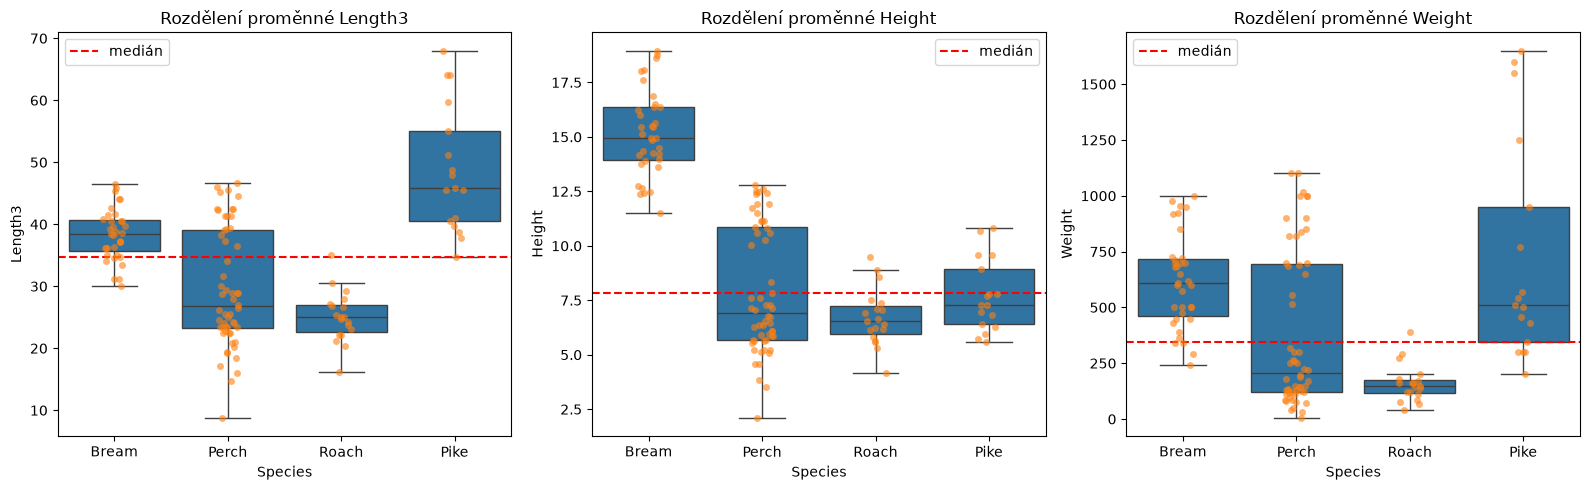

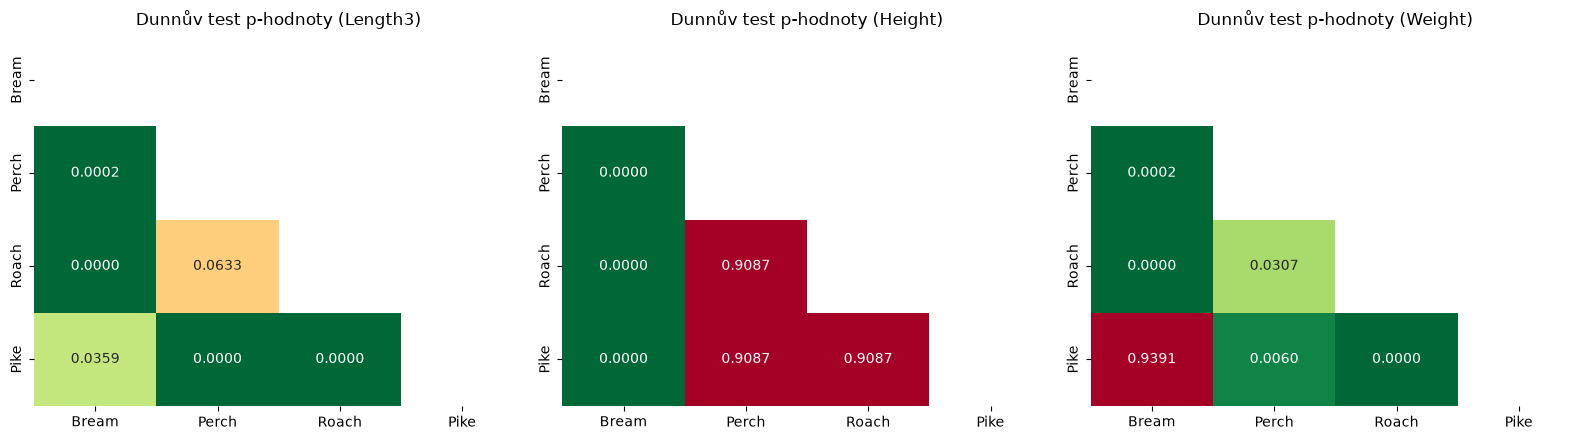

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# boxploty + body
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
df_sub = df[df['Species'].isin(classes)]
for ax, var in zip(axes, variables):
    sns.boxplot(data=df_sub, x='Species', y=var, order=classes, ax=ax, showfliers=False)
    sns.stripplot(data=df_sub, x='Species', y=var, order=classes, ax=ax, alpha=0.6)
    
    ax.axhline(df_sub[var].median(), color='red', linestyle='--', label='medián')
    ax.set_title(f'Rozdělení proměnné {var}')
    ax.legend()

plt.tight_layout()
plt.show()

# heatmapy Dunnova post-hoc testu s Holmovou korekcí
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, var in zip(axes, variables):
    dunn_res = sp.posthoc_dunn(df_sub, val_col=var, group_col='Species', p_adjust='holm').loc[classes, classes]
    mask = np.triu(np.ones_like(dunn_res, dtype=bool))  # jen dolní trojúhelník - odstranění duplicit
    
    sns.heatmap(
        dunn_res, mask=mask, annot=True, fmt=".4f",
        cmap="RdYlGn_r", vmin=0, vmax=0.1, cbar=False, ax=ax
    )
    ax.set_title(f'Dunnův test p-hodnoty ({var})')

plt.tight_layout()
plt.show()


Vícevýběrové testy potvrzují to, co je z vykreslených dat vidět pouhým okem, nulovou hypotézu Kruskal-Wallis testu o shodě rozdělení (polohy) ve všech skupinách jednoznačně zamítáme u všech tří proměnných. Alespoň jeden druh ryby se vždy v něčem statisticky významně liší od ostatních, což ovšem neznamená že při pohledu na proměnné zvlášť u post-hoc analýzy nemusí ke shodě dojít (`Weight` odděluje dva těžké druhy (Bream, Pike) od dvou lehčích (Perch, Roach) a `Height` jednoznačně odděluje jeden druh od ostatních) a u určitých dvojic hypotézu nemůžeme zamítnout. Výsledky odpovídají nalezeným údajům o daných rybách na internetu.